# Régression polynomiale (Prédiction du salaire)

Prédire le salaire d'un employé à partir de son niveau de poste.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from dotenv import load_dotenv

load_dotenv()
DATA_DIR = os.getenv("DATA_DIR")

df_sal = pd.read_csv(os.path.join(DATA_DIR, "Position_Salaries.csv"))
df_sal.head(10)

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


## Q5 a) Description de la base

In [2]:
df_sal.info()
df_sal.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Position  10 non-null     str  
 1   Level     10 non-null     int64
 2   Salary    10 non-null     int64
dtypes: int64(2), str(1)
memory usage: 372.0 bytes


,Level,Salary
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


- **10 postes**, 3 colonnes : `Position` (texte), `Level` (1 à 10), `Salary`.
- Chaque niveau correspond à un seul poste : `Position` et `Level` portent la même information, on n'utilise que `Level`.
- Salaires de 45 000 à 1 000 000 ; la moyenne est tirée vers le haut par les postes les plus élevés.

## Q5 b) Distribution et relation salaire / niveau

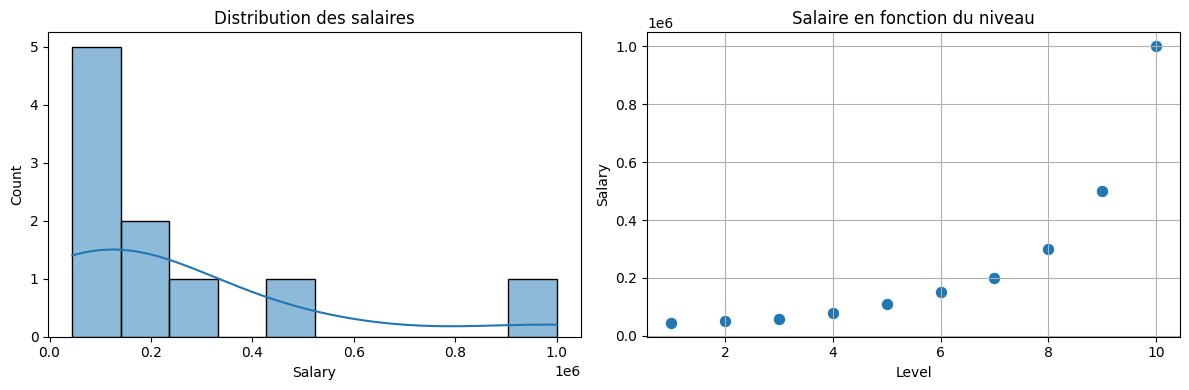

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_sal['Salary'], bins=10, kde=True, ax=axes[0])
axes[0].set_title('Distribution des salaires')

sns.scatterplot(x='Level', y='Salary', data=df_sal, s=80, ax=axes[1])
axes[1].set_title('Salaire en fonction du niveau')
axes[1].grid(True)

plt.tight_layout()
plt.show()

- La plupart des salaires sont faibles ; quelques valeurs très élevées (C-level, CEO) étirent la distribution vers la droite.
- Le salaire augmente avec le niveau, mais **pas de façon linéaire** : la croissance est lente au début puis **explose** pour les niveaux 8 à 10 (forme exponentielle).
- Une droite ne pourra pas suivre cette courbure → une **régression polynomiale** est plus adaptée.

## Variables et entraînement des modèles

In [4]:
X = df_sal.iloc[:, 1:-1].values   # Level (variable indépendante)
y = df_sal.iloc[:, -1].values     # Salary (variable dépendante)

# Régression linéaire
lr = LinearRegression()
lr.fit(X, y)

# Régression polynomiale de degré 4
pr = PolynomialFeatures(degree=4)
X_poly = pr.fit_transform(X)      # colonnes : 1, x, x², x³, x⁴
lr_2 = LinearRegression()
lr_2.fit(X_poly, y)

y_pred_lr = lr.predict(X)
y_pred_poly = lr_2.predict(X_poly)

print("R² linéaire     :", round(r2_score(y, y_pred_lr), 4))
print("R² polynomiale  :", round(r2_score(y, y_pred_poly), 4))

R² linéaire     : 0.669
R² polynomiale  : 0.9974


La régression polynomiale reste un modèle **linéaire en ses coefficients** : on crée les variables $x, x^2, x^3, x^4$ puis on applique une régression linéaire classique :
$$\hat{y} = b_0 + b_1 x + b_2 x^2 + b_3 x^3 + b_4 x^4$$

## Q6 a) Courbes de prédiction

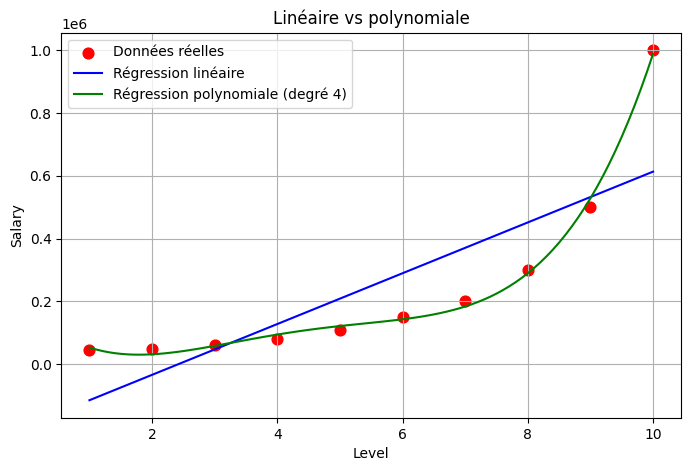

In [5]:
X_grid = np.arange(1, 10.01, 0.1).reshape(-1, 1)   # courbe lisse

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='red', s=60, label='Données réelles')
plt.plot(X, y_pred_lr, color='blue', label='Régression linéaire')
plt.plot(X_grid, lr_2.predict(pr.transform(X_grid)), color='green', label='Régression polynomiale (degré 4)')
plt.xlabel('Level'); plt.ylabel('Salary')
plt.title('Linéaire vs polynomiale')
plt.legend(); plt.grid(True)
plt.show()

- **Linéaire** (R² ≈ 0,67) : la droite passe loin des points ; elle prédit même des salaires **négatifs** pour les niveaux 1 et 2 et sous-estime fortement le CEO.
- **Polynomiale** (R² ≈ 0,997) : la courbe suit presque parfaitement les données.
- Attention : avec seulement 10 points, un degré 4 risque le **sur-apprentissage** ; il n'y a pas de jeu de test pour le vérifier.

## Q6 b) Prédiction pour un niveau 7,5

In [6]:
print(f'Linear Regression result : {lr.predict([[7.5]])}')
print(f'Polynomial Regression result : {lr_2.predict(pr.transform([[7.5]]))}')

Linear Regression result : [411257.57575758]
Polynomial Regression result : [225126.29297787]


- Le niveau 7,5 se situe entre *Partner* (200 000) et *Senior Partner* (300 000) : on attend un salaire d'environ **250 000**.
- **Linéaire : ≈ 411 000** → largement surestimé.
- **Polynomiale : ≈ 225 000** → cohérent avec l'intervalle attendu.
- La régression polynomiale est donc **bien plus précise** ici.

*Remarque :* l'énoncé utilise `pr.fit_transform([[7.5]])` ; on utilise `pr.transform` car le transformateur est déjà ajusté (même résultat ici, mais `transform` est la bonne pratique).